# Demo — Predicting Product Sales

Notebook demo end-to-end cho project (mô hình tự cài bằng numpy, lưu dạng `.npy`):

1. Đọc dữ liệu thô + EDA nhanh
2. Chạy pipeline tiền xử lý (`prepare_data`) → `data/processed/` + `models/preprocessor.npy`
3. Nạp 4 mô hình từ file `.npy` và đánh giá trên tập test (+ demo nhỏ grid search)
4. Dự đoán theo kịch bản bằng `SalesPredictor`

Chạy từ thư mục gốc của project: `jupyter notebook demo.ipynb` (hoặc `jupyter lab`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))  # đảm bảo import src/... khi mở notebook từ thư mục gốc

from src.config import TARGET_COL
from src.data.loader import load_raw

print("project root:", ROOT)

project root: D:\Code\predicting-product-sales


## 1. Dữ liệu thô & EDA nhanh

Đọc `data/raw/bigmart_sales.csv` (BigMart Sales, 8523×12) qua `loader.load_raw` — kiểm tra cột, không sửa dữ liệu.

In [2]:
df = load_raw()
print(f"shape: {df.shape}")
print("\n% giá trị thiếu theo cột:")
print((df.isna().mean() * 100).round(2).to_string())
print("\n5 dòng đầu:")
df.head()

shape: (8523, 12)

% giá trị thiếu theo cột:
Item_Identifier               0.00
Item_Weight                  17.17
Item_Fat_Content              0.00
Item_Visibility               0.00
Item_Type                     0.00
Item_MRP                      0.00
Outlet_Identifier             0.00
Outlet_Establishment_Year     0.00
Outlet_Size                  28.28
Outlet_Location_Type          0.00
Outlet_Type                   0.00
Item_Outlet_Sales             0.00

5 dòng đầu:


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


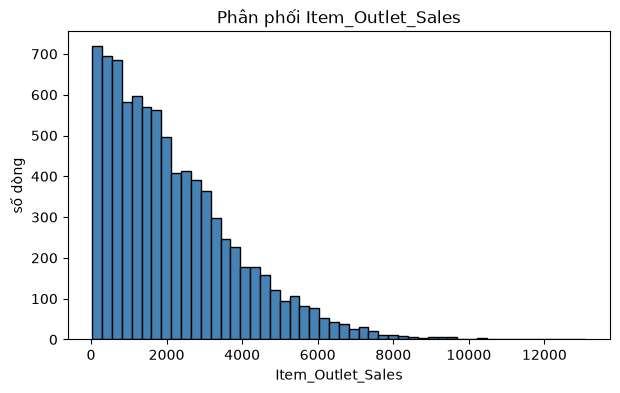

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df[TARGET_COL].dropna(), bins=50, color="steelblue", edgecolor="black")
ax.set_title(f"Phân phối {TARGET_COL}")
ax.set_xlabel(TARGET_COL)
ax.set_ylabel("số dòng")
plt.show()

## 2. Tiền xử lý end-to-end (`scripts/prepare_data.py`)

Chạy đúng pipeline: `load_raw → drop_invalid_rows → split (ngẫu nhiên, seed 42) → Cleaner → seasonal/popularity/customer_value → one-hot → lưu train/test.csv + preprocessor.npy`. Mọi thống kê chỉ fit trên train (không rò rỉ).

In [4]:
from scripts.prepare_data import main as run_prepare

run_prepare()  # in tiến trình + danh sách 52 đặc trưng

sau drop_invalid_rows: (8523, 12)
train: (6819, 12), test: (1704, 12)



Đã lưu D:\Code\predicting-product-sales\data\processed/train.csv ((6819, 53)) và test.csv ((1704, 53))
Đã lưu D:\Code\predicting-product-sales\save_models/preprocessor.npy
số đặc trưng: 52
danh sách đặc trưng:
  - Item_Weight
  - Item_Fat_Content=Low Fat
  - Item_Fat_Content=Regular
  - Item_Fat_Content=LF
  - Item_Fat_Content=reg
  - Item_Fat_Content=low fat
  - Item_Fat_Content=__other__
  - Item_Visibility
  - Item_Type=Fruits and Vegetables
  - Item_Type=Snack Foods
  - Item_Type=Household
  - Item_Type=Frozen Foods
  - Item_Type=Dairy
  - Item_Type=Baking Goods
  - Item_Type=Canned
  - Item_Type=Health and Hygiene
  - Item_Type=Soft Drinks
  - Item_Type=Meat
  - Item_Type=Breads
  - Item_Type=Hard Drinks
  - Item_Type=Others
  - Item_Type=Starchy Foods
  - Item_Type=Breakfast
  - Item_Type=Seafood
  - Item_Type=__other__
  - Item_MRP
  - Outlet_Identifier=OUT027
  - Outlet_Identifier=OUT013
  - Outlet_Identifier=OUT035
  - Outlet_Identifier=OUT018
  - Outlet_Identifier=OUT045
  -

In [5]:
train_df = pd.read_csv(ROOT / "data/processed/train.csv")
test_df = pd.read_csv(ROOT / "data/processed/test.csv")
print("train:", train_df.shape, "| test:", test_df.shape)
print("NaN còn lại (train/test):", int(train_df.isna().sum().sum()), "/", int(test_df.isna().sum().sum()))
print("cột cuối (target):", train_df.columns[-1])
print("số đặc trưng:", train_df.shape[1] - 1)

train: (6819, 53) | test: (1704, 53)
NaN còn lại (train/test): 0 / 0
cột cuối (target): Item_Outlet_Sales
số đặc trưng: 52


## 3. Nạp 4 mô hình từ file `.npy` & đánh giá trên tập test

`scripts/train.py` đã lưu mỗi mô hình thành `save_models/<model>.npy` (numpy) qua `save_model`. Ở đây nạp lại bằng `load_model` và tính MSE/MAE/RMSE/R2 — không train lại.

In [6]:
from src.metrics import evaluate_all
from src.models.base import load_model

X_test = test_df.drop(columns=[TARGET_COL]).to_numpy(float)
y_test = test_df[TARGET_COL].to_numpy(float)

rows = []
for name in ["linear_regression", "decision_tree", "random_forest", "gradient_boosting"]:
    model = load_model(ROOT / "save_models" / f"{name}.npy")  # nạp từ file .npy của numpy
    rows.append({"model": name, **evaluate_all(y_test, model.predict(X_test))})
results = pd.DataFrame(rows).sort_values("rmse").reset_index(drop=True)
results

,model,mse,mae,rmse,r2
0,gradient_boosting,1.115280e+06,740.561870,1056.068206,0.611808
1,random_forest,1.135940e+06,745.864950,1065.804800,0.604617
2,decision_tree,1.152400e+06,752.637894,1073.499160,0.598887
3,linear_regression,1.236646e+06,823.417335,1112.046076,0.569564


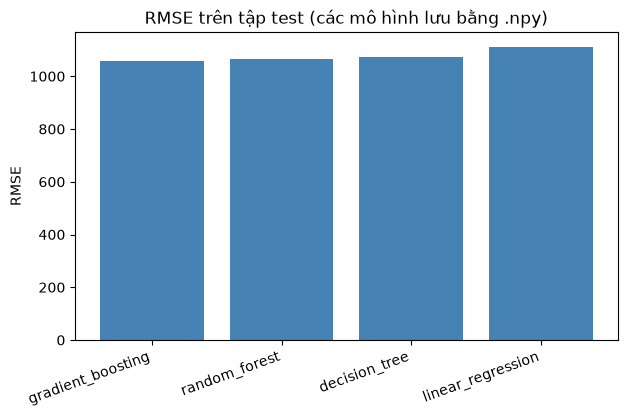

Mô hình tốt nhất: gradient_boosting


In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(results["model"], results["rmse"], color="steelblue")
ax.set_ylabel("RMSE")
ax.set_title("RMSE trên tập test (các mô hình lưu bằng .npy)")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.show()
print("Mô hình tốt nhất:", (ROOT / "save_models/best_model.txt").read_text().strip())

### 3b. Demo nhỏ: grid search (5-fold → 3-fold cho nhanh, 20% train)

 Minh họa `tuning.grid_search` tự viết: duyệt lưới tham số, mỗi tổ hợp chạy cross-validation bằng `clone()` của mô hình.

In [8]:
from src.models.decision_tree import DecisionTreeRegressor
from src.tuning import grid_search

X = train_df.drop(columns=[TARGET_COL]).to_numpy(float)
y = train_df[TARGET_COL].to_numpy(float)
rng = np.random.default_rng(42)
idx = rng.choice(len(X), size=int(0.2 * len(X)), replace=False)  # 20% train cho demo nhanh

best, res = grid_search(DecisionTreeRegressor(random_state=42), {"max_depth": [4, 8]}, X[idx], y[idx], k=3)
print("best_params:", best)

  1/2 {'max_depth': 4} -> rmse=1109.6197 (0.1s)


  2/2 {'max_depth': 8} -> rmse=1221.3681 (0.2s)
best_params: {'max_depth': np.float64(4.0)}


## 4. Dự đoán theo kịch bản bằng `SalesPredictor`

`SalesPredictor.load()` nạp `models/preprocessor.npy` + `save_models/best_model.txt` + `models/<best>.npy`, rồi áp lại đúng pipeline tiền xử lý khi dự đoán dữ liệu mới.

In [9]:
from scripts.predict_scenario import baseline_row, build_demo_scenarios
from src.predict import SalesPredictor

predictor = SalesPredictor.load()
print("mô hình đang dùng:", (ROOT / "save_models/best_model.txt").read_text().strip())

scenarios = build_demo_scenarios(df, baseline_row(df))
preds = predictor.predict(pd.DataFrame([sc for _, sc in scenarios]))
base = preds[0]
print(f"\n{'kịch bản':40s} {'doanh số dự đoán':>16s} {'chênh lệch':>12s} {'%':>8s}")
for (name, _), p in zip(scenarios, preds):
    print(f"{name:40s} {p:16.2f} {p - base:+12.2f} {(p - base) / base * 100:+7.2f}%")

# dự đoán 1 bản ghi đơn lẻ
print("\npredict_one(baseline) =", round(predictor.predict_one(dict(scenarios[0][1])), 2))

mô hình đang dùng: gradient_boosting
[bỏ qua] kịch bản quảng cáo: dataset không có AD_SPEND_COL
[bỏ qua] kịch bản ngày lễ/cuối năm: dataset không có DATE_COL

kịch bản                                 doanh số dự đoán   chênh lệch        %
baseline (điển hình)                              3165.81        +0.00   +0.00%
sản phẩm mới (product_freq=0)                     3411.43      +245.61   +7.76%

predict_one(baseline) = 3165.81


## 5. Kết luận

- Mô hình tốt nhất trên test: **gradient_boosting** (xem `reports/results.csv`, báo cáo `reports/REPORT.md`).
- Mô hình được lưu bằng **numpy `.npy`** trong `save_models/`, nạp lại bằng `load_model`/`SalesPredictor.load()`.
- Chi tiết thuật toán xem `docs/Algorithm/*.md`, đặc tả và cách hoạt động xem `docs/SPECIFICATION.md`.